# 07 · Champion v2: the logical dummy scorecard

## What this notebook is, and where it sits in the project

Notebook 06 showed that every challenger ranks borrowers clearly better than the v1 scorecard, and that most of the gap comes from **feature shapes and extra features**, not from complex interactions. That is good news: a gap made of shapes and features can be closed *inside* a scorecard, without giving up a points table, reason codes or logical points.

This notebook builds that scorecard, **champion v2** (D-028), in four moves, each tested in the 2026-11-23 audit:

1. **One coefficient per bin** (dummy coding) instead of one per feature.
2. **Interaction characteristics**: loan size and borrowing history binned *inside each country*.
3. **Wider feature set**: every feature that passes the stability and logic screens.
4. **Logical points by construction**: the bin points are constrained to follow the risk order of the bins.

Then it compares v2 with v1, the challengers and Bondora on the same loans, and decides.

As in notebooks 01 to 06, each step has **Why this step**, **the code**, **What the result shows** and **Recommended action**. The champion itself is built by `pdengine.champion.fit_champion`, the same function `make train` runs, so the notebook and the pipeline cannot disagree.

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **WoE scorecard (v1)** | Each feature is replaced by the weight of evidence of its bin, and the logistic regression gives **one coefficient per feature**. Each feature's points therefore keep the shape of its single-feature WoE. |
| **Dummy-coded scorecard** | Each bin gets its **own** coefficient (a 0/1 column per bin). The fit can adjust each feature's shape for the other features. |
| **Partial vs marginal effect** | The marginal effect of loan size is what you see looking at loan size alone; the partial effect is what remains after allowing for the other features (for example country). A joint fit estimates partial effects. |
| **Interaction characteristic** | A characteristic built from two features, here country × loan size: each country has its own bins (Siddiqi, chapter 6). |
| **Ridge penalty** | A small cost on large coefficients that keeps estimates stable when bins are small or features overlap. |
| **Order constraint** | A rule that the points of an ordered feature must follow the risk order of its bins: a safer bin never gets fewer points. It makes the points *logical by construction* (D-023). |
| **L-BFGS-B** | A standard optimisation method that accepts simple bounds; the order constraints are written as bounds on the steps between neighbouring bins. |
| **Flat characteristic** | A characteristic whose points barely change across its bins (less than 2 points): it adds nothing to the decision and is removed. |
| **PSI of the score** | Population stability index of the final score between train and out-of-time: how much the score distribution moved. |

## Step 0. Setup

### Why this step
Load the libraries, the pipeline functions and the outputs of notebooks 05 and 06 (the v1 champion and the challengers' predictions).

In [1]:
import logging
logging.disable(logging.WARNING)
import cvxpy  # noqa: F401  load before pandas on Windows (D-026)
import pickle
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from optbinning import BinningProcess

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
PROC = ROOT / "data" / "processed"
for f in ["model_samples.parquet", "binning_process.pkl", "scorecard.json", "challenger_predictions.parquet"]:
    assert (PROC / f).exists(), f"{f} missing: run make train and notebook 06 first"
try:
    from pdengine import settings as S
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine import settings as S
from pdengine.champion import (CountryBins, LogicalScorecard, _bin_sort_key, fit_champion,
                               labels_for, ordered_groups)
from pdengine.dataset import load_model_data
from pdengine.registry import load_registry
from pdengine.scorecard import Scorecard, brier, gini, ks
from pdengine.selection import fit_bins, psi, screen_features, transform

con = duckdb.connect(str(S.DB_PATH), read_only=True)
reg = load_registry()
SEED = S.SEED
BLUE, GREY, ORANGE, GREEN, PURPLE = "#2a78d6", "#b5b3ad", "#d97a2b", "#3c9a5f", "#7b5ea7"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print("ready")

ready


### What the result shows
Libraries and inputs loaded.

### Recommended action
None.

## Step 1. Data, the v1 champion and the challengers

### Why this step
Everything is compared on the same loans. The v1 champion's PDs are recomputed from its saved bins and coefficients; the challengers' PDs come from notebook 06. The forward-chaining folds (fit up to 2017 → check 2018; fit up to 2018 → check 2019) are the same as in notebook 06.

In [2]:
samples = pd.read_parquet(PROC / "model_samples.parquet")
data = load_model_data(con, samples, reg)
X, y, sample, country = data.X, data.y, data.sample, data.country
is_train, is_test, is_oot = sample.eq("train"), sample.eq("test"), sample.eq("oot")
year = data.issue_date.dt.year
FOLDS = [(is_train & (year < v), is_train & (year == v)) for v in [2018, 2019]]

bins_v1 = BinningProcess.load(str(PROC / "binning_process.pkl"))
v1 = Scorecard.from_json(PROC / "scorecard.json")
woe_v1 = transform(bins_v1, X, "woe")
pd_v1 = v1.predict_pd(woe_v1)
challengers = pd.read_parquet(PROC / "challenger_predictions.parquet").loc[X.index]
SIX = v1.features
print(f"{len(X):,} loans. v1 features: {SIX}")
print("Challengers from notebook 06:", [c for c in challengers.columns if c not in ("sample", "v1 champion scorecard")])

155,725 loans. v1 features: ['country_bureau_grade', 'days_since_first_loan', 'days_since_last_loan', 'HomeOwnershipType', 'AppliedAmount', 'income_vs_country_median']
Challengers from notebook 06: ['LightGBM, 6 features', 'LightGBM, 24 features', 'CatBoost, 24 features', 'EBM, additive', 'EBM, 10 interactions', 'Bondora PD']


### What the result shows
The same 155,725 loans, the v1 features and the challengers' predictions.

### Recommended action
None.

## Step 2. Diagnosis: why is the v1 scorecard weaker?

### Why this step
Before changing the champion we need to know *what* it misses. Three checks, each isolating one cause:

* **(a) One coefficient per feature.** Same six features, same v1 bins: WoE logit (one coefficient per feature) vs dummy logit (one per bin).
* **(b) Country-specific shapes.** The train default rate by loan size, inside each country.
* **(c) Features left out.** Which features the EBM challenger uses that v1's selection rules removed, and why they were removed.

In [3]:
from sklearn.linear_model import LogisticRegression

lab_v1 = transform(bins_v1, X, "bins")[SIX].astype(str)
Z = pd.get_dummies(lab_v1).astype(float)
dummy = LogisticRegression(C=0.1, max_iter=5000).fit(Z[is_train], y[is_train])
p_dummy = pd.Series(dummy.predict_proba(Z)[:, 1], index=X.index)
print("(a) same six features, same bins")
print(pd.DataFrame({"WoE logit (v1)": [gini(y[is_test], pd_v1[is_test]), gini(y[is_oot], pd_v1[is_oot])],
                    "dummy logit": [gini(y[is_test], p_dummy[is_test]), gini(y[is_oot], p_dummy[is_oot])]},
                   index=["test Gini", "oot Gini"]).round(3))

print("\n(b) train default rate (%) by loan-size decile, inside each country")
q = pd.qcut(X.loc[is_train, "AppliedAmount"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
display((pd.DataFrame({"y": y[is_train], "decile": q, "country": country[is_train]})
         .pivot_table(index="country", columns="decile", values="y", aggfunc="mean") * 100).round(0))

print("(c) features the EBM challenger uses, and what v1's selection did with them")
ebm = pickle.load(open(PROC / "challenger_ebm.pkl", "rb"))["model"]
imp = pd.Series(ebm.term_importances(), index=ebm.term_names_)
imp = imp[[" & " not in t for t in imp.index]].sort_values(ascending=False)
v1_table = pd.read_csv(PROC / "feature_selection.csv", index_col=0)
reason = v1_table["reason"].reindex(imp.index).fillna("not a v1 candidate")
reason[[f for f in imp.index if f in SIX]] = "in v1"
pd.DataFrame({"EBM importance": imp.round(3), "v1 selection": reason})

(a) same six features, same bins
           WoE logit (v1)  dummy logit
test Gini           0.459        0.468
oot Gini            0.368        0.378

(b) train default rate (%) by loan-size decile, inside each country


decile,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
country,,,,,,,,,,
EE,20.0,18.0,16.0,16.0,17.0,19.0,19.0,21.0,20.0,25.0
ES,64.0,63.0,47.0,54.0,58.0,57.0,54.0,53.0,54.0,63.0
FI,34.0,39.0,25.0,28.0,47.0,48.0,42.0,39.0,46.0,44.0


(c) features the EBM challenger uses, and what v1's selection did with them


,EBM importance,v1 selection
country_bureau_grade,0.671,in v1
days_since_first_loan,0.250,in v1
AppliedAmount,0.194,in v1
AmountOfPreviousLoansBeforeLoan,0.193,kept
HomeOwnershipType,0.185,in v1
days_since_last_loan,0.126,in v1
Education,0.111,IV 0.019 below 0.02
NewCreditCustomer,0.107,duplicates AmountOfPreviousLoansBeforeLoan (correlation ...
Amount,0.077,duplicates AppliedAmount (correlation 0.96)
income_vs_country_median,0.069,in v1


### What the result shows
* **(a) One coefficient per feature costs about 0.01.** With exactly the same six features and the same bins, giving each bin its own coefficient raises test Gini from 0.459 to 0.468 and out-of-time from 0.368 to 0.378. The WoE logit forces each feature to keep its single-feature shape, even where other features already explain part of it.
* **(b) Loan size means different things in each country.**
  * In Estonia risk rises gently with size, from 16% to 25% in the largest decile.
  * In Spain the smallest and largest loans are the riskiest.
  * In Finland the third and fourth deciles are the safest (25 to 28%), and risk jumps to about 47% from the fifth decile.
  One pooled set of bins cannot express three different shapes.
* **(c) The EBM leans on features that v1's rules removed.** `AmountOfPreviousLoansBeforeLoan` passed selection but was removed by the sign check. `Education` missed the IV cut by 0.001. `NewCreditCustomer`, `Amount`, `NoOfPreviousLoansBeforeLoan` and `LiabilitiesTotal` fell to the correlation rule. Those rules protect a one-coefficient model; they are not statements that the features carry no information.

### Recommended action
Change the scorecard in exactly these three places: dummy coding, country-specific bins for loan size and history, and screens instead of v1's selection rules.

## Step 3. Screens: which features may enter v2

### Why this step
v1's rules (IV of at least 0.02, correlation below 0.7, VIF below 5, coefficient signs) exist to protect a model with one coefficient per feature: a weak or overlapping feature can flip such a model's signs. v2 is fitted jointly with a ridge penalty and order constraints, so those rules are no longer needed. What still matters is **stability and logic**:

* **population shift**: PSI between train and out-of-time above 0.25 (feature values only; out-of-time outcomes are never used);
* **country effect**: the within-country check of D-018 (a pooled pattern that disappears inside each country);
* **a derived feature replaces its raw inputs** (country with bureau grade replaces country and the raw bureau scores; income relative to the country median replaces raw income).

The bins are finer than v1's (at least 2% of train loans per bin, from 1% pre-bins), because a joint fit can use more resolution.

In [4]:
bins_v2 = fit_bins(X[is_train], y[is_train], S.V2_MIN_BIN_SIZE, S.V2_MIN_PREBIN_SIZE, S.V2_MAX_N_PREBINS)
screen = screen_features(bins_v2, X, y, sample, country, reg)
print(f"Kept {len(screen.shortlist)} features:", screen.shortlist)
screen.table[["iv", "psi_oot", "rho_median", "reason"]].round(3)

Kept 16 features: ['country_bureau_grade', 'days_since_first_loan', 'NoOfPreviousLoansBeforeLoan', 'days_since_last_loan', 'AmountOfPreviousLoansBeforeLoan', 'NewCreditCustomer', 'HomeOwnershipType', 'ExistingLiabilities', 'AppliedAmount', 'Amount', 'LiabilitiesTotal', 'income_vs_country_median', 'Education', 'PreviousEarlyRepaymentsCountBeforeLoan', 'ApplicationSignedHour', 'ApplicationSignedWeekday']


,iv,psi_oot,rho_median,reason
name,,,,
country_bureau_grade,0.569,0.162,NaN,kept
Country,0.517,0.159,NaN,input of country_bureau_grade
CreditScoreEeMini,0.505,0.116,NaN,input of country_bureau_grade
days_since_first_loan,0.268,0.036,-0.909,kept
NoOfPreviousLoansBeforeLoan,0.196,0.022,-0.976,kept
days_since_last_loan,0.191,0.035,-0.907,kept
AmountOfPreviousLoansBeforeLoan,0.177,0.032,-0.733,kept
NewCreditCustomer,0.166,0.005,-1.000,kept
MonthlyPaymentDay,0.123,0.249,0.114,country effect (within-country correlation +0.11)


### What the result shows
16 features are kept, and 8 removed for a reason that still matters:
* three are replaced by `country_bureau_grade` (country and the two raw bureau scores);
* raw income is replaced by `income_vs_country_median`;
* `MonthlyPaymentDay` is a country effect;
* three fail the stability check: `VerificationType` (PSI 1.00), `EmploymentDurationCurrentEmployer` (0.32) and `LoanDuration` (0.28).

Features v1 dropped for low IV or for correlation are back in the candidate set.

### Recommended action
Use the kept features as v2's starting set.

## Step 4. Interaction characteristics: bins inside each country

### Why this step
Step 2(b) showed that loan size does not mean the same thing in each country, and notebook 06 found the strongest interactions between country and the two history features. Instead of three separate scorecards (each with a third of the data), the three features are binned **inside each country** and enter the one scorecard as country-specific characteristics. Each country gets its own optimal bins (at least 5% of that country's train loans, monotone where economics says so).

days_since_last_loan: bins and train default rate (%) per country


,loans,default_rate
bin,,
"EE:(-inf, 62.50)",5289,24.4
"EE:[62.50, 64.50)",2872,21.3
"EE:[64.50, 69.50)",2329,18.3
"EE:[69.50, 83.50)",3222,17.0
"EE:[83.50, 184.50)",9465,14.8
"EE:[184.50, 264.50)",2171,13.5
"EE:[264.50, inf)",4092,8.8
EE:Missing,13908,23.1
"ES:(-inf, 98.50)",2487,47.8


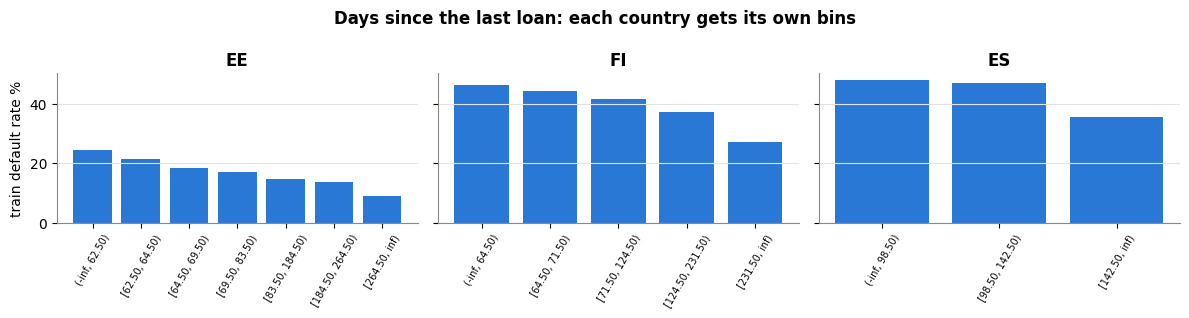

In [5]:
cross = CountryBins().fit(X[is_train], y[is_train], country[is_train])
f = "days_since_last_loan"
lab = cross.transform(X, country, f)
t = pd.DataFrame({"bin": lab, "y": y})[is_train].groupby("bin")["y"].agg(loans="size", default_rate="mean")
t["default_rate"] = (t["default_rate"] * 100).round(1)
t = t.loc[sorted(t.index, key=_bin_sort_key)]
print(f"{f}: bins and train default rate (%) per country")
display(t)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, c in zip(axes, S.CROSS_COUNTRIES):
    sub = t[t.index.str.startswith(c + ":") & ~t.index.str.contains("Missing")]
    ax.bar(range(len(sub)), sub["default_rate"], color=BLUE)
    ax.set_title(c); ax.set_xticks(range(len(sub)), [s.split(":")[1] for s in sub.index], rotation=60, fontsize=7)
axes[0].set_ylabel("train default rate %")
fig.suptitle("Days since the last loan: each country gets its own bins", fontweight="bold")
plt.tight_layout(); plt.show()

### What the result shows
* The default rate falls as the time since the last loan grows, in every country, but at very different levels and speeds:
  * Estonia: 24% → 9%
  * Finland: 46% → 27%
  * Spain: 48% → 35%
* The "Missing" group (a first loan, so no previous loan) is also very different: 23% in Estonia, 43% in Finland, 64% in Spain.
* Each country gets its own cut points (Finland's last bin starts at 232 days, Estonia's at 265). A pooled bin would mix these patterns.

### Recommended action
Use the country bins for `AppliedAmount`, `days_since_last_loan` and `days_since_first_loan`.

## Step 5. The logical fit: points that follow the risk order

### Why this step
With one coefficient per bin, nothing stops the fit from giving a safer bin fewer points than a riskier one (a noisy small bin, or two overlapping features sharing the effect). A bank validator rejects such a points table (D-023). So inside every ordered feature, and every country of a crossed feature, the bins are sorted from riskiest to safest by their train default rate, and the coefficients are **constrained to follow that order**. Unordered categories (home ownership, bureau grade) and "Missing" bins are free.

We fit the same model twice, without and with the constraints, and count the broken orders.

In [6]:
FEATS = screen.shortlist
lab_tr = labels_for(bins_v2, cross, X[is_train], country[is_train], FEATS)
groups = ordered_groups(bins_v2, cross, lab_tr, y[is_train])
lab_all = labels_for(bins_v2, cross, X, country, FEATS)
free = LogicalScorecard().fit(lab_tr, y[is_train], [])
free.groups = [[c for c in g if c in free.columns] for g in groups]     # to count its violations
logical = LogicalScorecard().fit(lab_tr, y[is_train], groups)
p_free, p_logical = free.predict_pd(lab_all), logical.predict_pd(lab_all)


def cv(feats, constrained=True):
    out = []
    for fit_on, check_on in FOLDS:
        lt = labels_for(bins_v2, cross, X[fit_on], country[fit_on], feats)
        g = ordered_groups(bins_v2, cross, lt, y[fit_on]) if constrained else []
        m = LogicalScorecard().fit(lt, y[fit_on], g)
        out.append(gini(y[check_on], m.predict_pd(labels_for(bins_v2, cross, X[check_on], country[check_on], feats))))
    return np.mean(out)


pd.DataFrame({
    "cells": [len(free.columns), len(logical.columns)],
    "ordered groups": [len(groups), len(groups)],
    "groups with a broken order": [len(free.order_violations()), len(logical.order_violations())],
    "validation Gini": [cv(FEATS, False), cv(FEATS, True)],
    "test Gini": [gini(y[is_test], p_free[is_test]), gini(y[is_test], p_logical[is_test])],
    "oot Gini": [gini(y[is_oot], p_free[is_oot]), gini(y[is_oot], p_logical[is_oot])],
}, index=["unconstrained dummy scorecard", "logical (constrained)"]).round(4)

,cells,ordered groups,groups with a broken order,validation Gini,test Gini,oot Gini
unconstrained dummy scorecard,120,18,9,0.4494,0.4858,0.4078
logical (constrained),120,18,0,0.4483,0.4801,0.4013


### What the result shows
* **Without the constraints, 9 of the 18 ordered groups break their risk order.** A safer bin gets fewer points than a riskier one, which a validator would reject.
* **With the constraints, none does.** The cost is small: 0.001 in year-ahead validation, 0.006 on test and 0.007 out of time. That is the price of a points table that always makes sense.

### Recommended action
Keep the constraints.

## Step 6. Parsimony: drop flat characteristics, then fit the champion

### Why this step
Some characteristics end up with almost the same points in every bin: the constraints and the penalty have shrunk them to nothing because other features already carry their information. A characteristic that never changes a decision is only clutter on the points table and in monitoring, so features whose points vary by less than 2 are removed and the scorecard is refitted (repeated until none is flat).

`fit_champion` runs steps 3 to 6 in one call. It is the function `make train` uses.

In [7]:
v2 = fit_champion(X, y, sample, country, reg)
pd_v2 = v2.predict_pd(X, country)
print("Flat characteristics removed:", v2.flat)
print(f"Champion v2 features ({len(v2.features)}):", v2.features)
print("Converged:", v2.card.converged, "| broken orders:", v2.card.order_violations())
print(f"Validation Gini {cv(v2.features):.4f} | test {gini(y[is_test], pd_v2[is_test]):.4f} | oot {gini(y[is_oot], pd_v2[is_oot]):.4f}")

Flat characteristics removed: ['NewCreditCustomer', 'ExistingLiabilities', 'Amount', 'LiabilitiesTotal', 'PreviousEarlyRepaymentsCountBeforeLoan', 'ApplicationSignedWeekday']
Champion v2 features (10): ['country_bureau_grade', 'days_since_first_loan', 'NoOfPreviousLoansBeforeLoan', 'days_since_last_loan', 'AmountOfPreviousLoansBeforeLoan', 'HomeOwnershipType', 'AppliedAmount', 'income_vs_country_median', 'Education', 'ApplicationSignedHour']
Converged: True | broken orders: []


Validation Gini 0.4519 | test 0.4802 | oot 0.4013


### What the result shows
* Six characteristics end up flat: `NewCreditCustomer`, `ExistingLiabilities`, `Amount`, `LiabilitiesTotal`, `PreviousEarlyRepaymentsCountBeforeLoan` and `ApplicationSignedWeekday`. Their information is already carried by tenure, previous loans and loan size.
* **Champion v2 has 10 characteristics.** Removing the flat ones costs nothing: validation 0.452, test 0.480, out-of-time 0.401. The fit converged, and no order is broken.

### Recommended action
Adopt these features as champion v2.

## Step 7. The points table and reason codes

### Why this step
A scorecard is only useful if a person can read it. Points use the same scaling as v1 (600 points at good:bad odds of 30:1, 20 points to double the odds). Each loan's score is the sum of its points, one cell per characteristic. The **reason codes** for a decline are the characteristics where the applicant lost most points compared with the best cell of that characteristic, the standard "points below maximum" method (Siddiqi, chapter 12).

In [8]:
points = v2.card.points_table()
spread = points.groupby("feature", sort=False)["points"].agg(lowest="min", highest="max")
spread["range"] = spread["highest"] - spread["lowest"]
display(spread.sort_values("range", ascending=False))
print("Points for days_since_last_loan in Finland:")
display(points[(points["feature"] == "days_since_last_loan") & points["bin"].str.startswith("FI:")][["bin", "points"]])


def reasons(i, top=3):
    """The `top` characteristics where loan i lost most points vs the best cell."""
    lab = v2.labels(X.loc[[i]], country.loc[[i]]).iloc[0]
    best = points.groupby("feature")["points"].max()
    got = {f: points[(points["feature"] == f) & (points["bin"] == lab[f])]["points"].iloc[0] for f in v2.features}
    lost = pd.Series({f: best[f] - got[f] for f in v2.features}).sort_values(ascending=False)
    return lost.head(top)


riskiest = pd_v2[is_test].idxmax()
print(f"Example: test loan with the highest PD ({pd_v2[riskiest]:.1%}), score {v2.card.score(v2.labels(X.loc[[riskiest]], country.loc[[riskiest]])).iloc[0]:.0f}")
reasons(riskiest).rename("points lost vs best cell").to_frame()

,lowest,highest,range
feature,,,
country_bureau_grade,34,76,42
days_since_last_loan,41,67,26
days_since_first_loan,45,69,24
AppliedAmount,40,63,23
HomeOwnershipType,46,61,15
AmountOfPreviousLoansBeforeLoan,45,54,9
ApplicationSignedHour,47,55,8
Education,49,57,8
income_vs_country_median,49,56,7


Points for days_since_last_loan in Finland:


,bin,points
47,"FI:(-inf, 64.50)",43
48,"FI:[64.50, 71.50)",46
49,"FI:[71.50, 124.50)",48
50,"FI:[124.50, 231.50)",53
51,"FI:[231.50, inf)",64
52,FI:Missing,56


Example: test loan with the highest PD (83.2%), score 456


,points lost vs best cell
country_bureau_grade,42
days_since_first_loan,23
days_since_last_loan,21


### What the result shows
* **The bureau grade within country moves the score most**, with a range of 42 points. The two history features (26 and 24 points) and loan size (23) come next, then home ownership (15). The rest move the score by 3 to 9 points.
* In Finland, a loan taken within about two months of the previous one scores 43 points; a gap of more than 232 days scores 64.
* The test loan with the highest PD (83%) scores 456. Its three reason codes, in points lost against the best cell:
  * the bureau grade (−42);
  * a short customer tenure (−23);
  * a very recent previous loan (−21).

These are reasons a credit officer can explain to an applicant.

### Recommended action
Use the points-below-maximum reason codes in the Phase 4 decision tables and the `/score` API.

## Step 8. Results: v2 against v1, the challengers and Bondora

### Why this step
The decision uses the same rules as notebook 06: validation and test choose, out-of-time reports. Paired bootstraps (the same resampled loans scored by both models) say whether a difference is larger than chance.

In [9]:
def paired_diff(mask, a, b, n_boot=300):
    rng = np.random.default_rng(SEED)
    t, sa, sb = y[mask].to_numpy(), a[mask].to_numpy(), b[mask].to_numpy()
    d = [gini(t[i], sa[i]) - gini(t[i], sb[i]) for i in (rng.integers(0, len(t), len(t)) for _ in range(n_boot))]
    return np.percentile(d, [2.5, 97.5])


ALLM = {"v1 champion scorecard": pd_v1, "champion v2 (logical dummy scorecard)": pd_v2}
ALLM.update({c: challengers[c] for c in challengers.columns if c not in ("sample", "v1 champion scorecard")})
rows = []
for name, p in ALLM.items():
    r = {"model": name, "test": gini(y[is_test], p[is_test]), "oot": gini(y[is_oot], p[is_oot]),
         "oot_ks": ks(y[is_oot], p[is_oot]), "test_brier": brier(y[is_test], p[is_test])}
    r.update({f"oot_{c}": gini(y[is_oot & country.eq(c)], p[is_oot & country.eq(c)]) for c in ["EE", "FI", "ES"]})
    rows.append(r)
results = pd.DataFrame(rows).set_index("model")
display(results.round(3))
for s_name, m in [("test", is_test), ("oot", is_oot)]:
    lo, hi = paired_diff(m, pd_v2, pd_v1)
    print(f"{s_name}: v2 minus v1 {gini(y[m], pd_v2[m]) - gini(y[m], pd_v1[m]):+.3f} (95% {lo:+.3f} to {hi:+.3f})")
lo, hi = paired_diff(is_oot, pd_v2, data.bondora_pd)
print(f"oot: v2 minus Bondora PD {gini(y[is_oot], pd_v2[is_oot]) - gini(y[is_oot], data.bondora_pd[is_oot]):+.3f} (95% {lo:+.3f} to {hi:+.3f})")
lo, hi = paired_diff(is_test, pd_v2, challengers["EBM, 10 interactions"])
print(f"test: v2 minus EBM (10 interactions) {lo:+.3f} to {hi:+.3f}")
lab_v1_cv = []
for fit_on, check_on in FOLDS:
    import statsmodels.api as sm
    m = sm.Logit(y[fit_on], sm.add_constant(woe_v1.loc[fit_on, SIX])).fit(disp=0)
    lab_v1_cv.append(gini(y[check_on], m.predict(sm.add_constant(woe_v1.loc[check_on, SIX]))))
print(f"validation (forward-chaining): v1 {np.mean(lab_v1_cv):.4f}, v2 {cv(v2.features):.4f}")

,test,oot,oot_ks,test_brier,oot_EE,oot_FI,oot_ES
model,,,,,,,
v1 champion scorecard,0.459,0.368,0.267,0.185,0.323,0.154,0.117
champion v2 (logical dummy scorecard),0.480,0.401,0.278,0.182,0.350,0.287,0.155
"LightGBM, 6 features",0.498,0.416,0.296,0.179,0.339,0.284,0.143
"LightGBM, 24 features",0.515,0.439,0.310,0.177,0.394,0.281,0.175
"CatBoost, 24 features",0.516,0.449,0.320,0.177,0.395,0.325,0.184
"EBM, additive",0.501,0.417,0.299,0.179,0.352,0.198,0.148
"EBM, 10 interactions",0.513,0.426,0.303,0.177,0.347,0.265,0.165
Bondora PD,0.414,0.405,0.300,0.193,0.359,0.284,0.162


test: v2 minus v1 +0.021 (95% +0.017 to +0.025)


oot: v2 minus v1 +0.033 (95% +0.028 to +0.038)


oot: v2 minus Bondora PD -0.004 (95% -0.021 to +0.014)


test: v2 minus EBM (10 interactions) -0.037 to -0.028


validation (forward-chaining): v1 0.4427, v2 0.4519


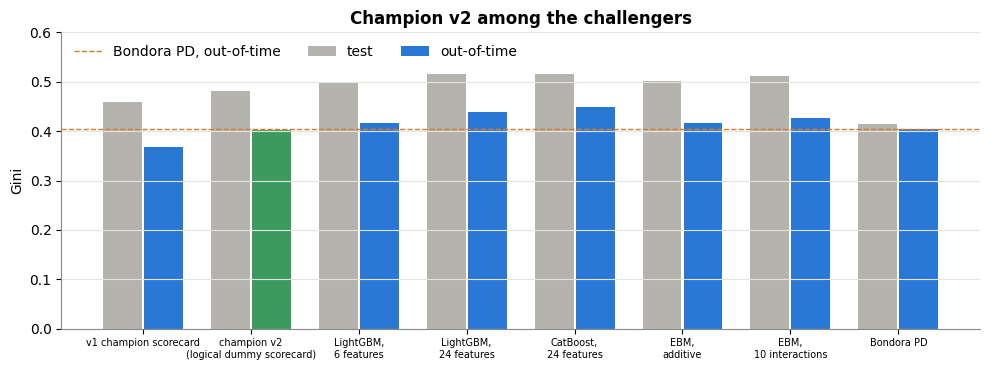

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
names = list(results.index)
xs = np.arange(len(names))
ax.bar(xs - 0.19, results["test"], width=0.36, color=GREY, label="test")
ax.bar(xs + 0.19, results["oot"], width=0.36, color=[GREEN if "v2" in n else BLUE for n in names], label="out-of-time")
ax.axhline(gini(y[is_oot], data.bondora_pd[is_oot]), color=ORANGE, linestyle="--", linewidth=1, label="Bondora PD, out-of-time")
ax.set_xticks(xs, [n.replace(" (", "\n(").replace(", ", ",\n") for n in names], fontsize=7)
ax.set_ylabel("Gini"); ax.set_ylim(0, 0.6); ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Champion v2 among the challengers")
plt.tight_layout(); plt.show()

### What the result shows
| | Validation | Test Gini | OOT Gini | OOT Finland |
|---|---|---|---|---|
| v1 champion scorecard | 0.443 | 0.459 | 0.368 | 0.154 |
| **champion v2** | **0.452** | **0.480** | **0.401** | **0.287** |
| EBM, 10 interactions | 0.456 | 0.513 | 0.426 | 0.265 |
| CatBoost, 24 features | 0.462 | 0.516 | 0.449 | 0.325 |
| Bondora PD | | 0.414 | 0.405 | 0.284 |

* **v2 beats v1 everywhere.**
  * Test: +0.021 (95% +0.017 to +0.025).
  * Out of time: +0.033 (+0.028 to +0.038).
  * Year-ahead validation: +0.009.
* **The largest gain is in Finland** (0.154 → 0.287 out of time), exactly where notebook 06 located v1's weakness.
* **v2 matches Bondora's own model out of time.** The difference is −0.004 (−0.021 to +0.014), using no interest rate and no repayment history.
* **The challengers still lead by about 0.03 test Gini.** The remaining gap is the price of a points table with logical, readable cells: the boosting models use finer shapes and interactions beyond country.

### Recommended action
Promote v2 to champion (D-028). Keep the EBM as main challenger and CatBoost and LightGBM as benchmarks. If a future refit shows the EBM's lead growing, that is the signal to revisit the champion's form.

## Step 9. Stability and calibration

### Why this step
A champion must also be stable: its score distribution should not move much between development and out-of-time (PSI of the score), and its PDs must be checked against observed default rates. Like every model here, v2 learned the 2016 to 2019 default level.

Score PSI train vs out-of-time, v1: 0.089
Score PSI train vs out-of-time, v2: 0.186


,observed,v1 mean PD,v2 mean PD
train,31.4,31.4,31.4
test,31.4,31.5,31.5
oot,14.4,26.9,26.0


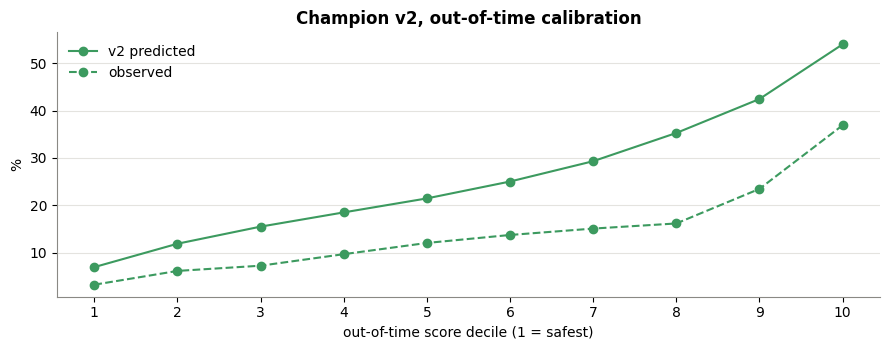

In [11]:
score_v2 = v2.card.score(v2.labels(X, country))
score_v1 = v1.score(woe_v1)
cuts = lambda s: pd.qcut(s[is_train], 10, retbins=True, duplicates="drop")[1]
for name, s in [("v1", score_v1), ("v2", score_v2)]:
    edges = cuts(s); edges[0], edges[-1] = -np.inf, np.inf
    print(f"Score PSI train vs out-of-time, {name}: {psi(pd.cut(s[is_train], edges), pd.cut(s[is_oot], edges)):.3f}")
cal = pd.DataFrame({s_name: {"observed": y[m].mean(), "v1 mean PD": pd_v1[m].mean(), "v2 mean PD": pd_v2[m].mean()}
                    for s_name, m in [("train", is_train), ("test", is_test), ("oot", is_oot)]}).T
display((cal * 100).round(1))
fig, ax = plt.subplots()
d = pd.DataFrame({"pd": pd_v2[is_oot], "y": y[is_oot]})
d["decile"] = pd.qcut(d["pd"].rank(method="first"), 10, labels=False) + 1
g = d.groupby("decile").agg(predicted=("pd", "mean"), observed=("y", "mean")) * 100
ax.plot(g.index, g["predicted"], color=GREEN, marker="o", label="v2 predicted")
ax.plot(g.index, g["observed"], color=GREEN, marker="o", linestyle="--", label="observed")
ax.set_xlabel("out-of-time score decile (1 = safest)"); ax.set_ylabel("%"); ax.set_xticks(range(1, 11))
ax.set_title("Champion v2, out-of-time calibration"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### What the result shows
* **The score PSI is 0.19 for v2 against 0.09 for v1.** That is a moderate shift (0.10 to 0.25), below the usual action level of 0.25. It is larger because v2's country-specific bins react to Finland's new loan sizes after the 2019–2020 interest-rate cap. v1's pooled bins hid that shift, but they also ranked Finnish borrowers much worse.
* **Calibration:** in time v2 is exact (31.5% predicted vs 31.4% observed). Out of time it predicts 26.0% against 14.4% observed, like every model here. The deciles keep the right order; the level is the problem.

### Recommended action
Recalibrate v2 per country in Phase 4 (calibrate on 2020, test on 2021, Jeffreys test per grade).

## Step 10. Check against the pipeline and save

### Why this step
`make train` must produce exactly the champion built here. The pipeline wrote `champion_v2.pkl`; we reload it and compare PDs.

In [12]:
saved = pickle.load(open(PROC / "champion_v2.pkl", "rb"))
assert saved.features == v2.features, (saved.features, v2.features)
diff = float(np.abs(saved.predict_pd(X, country) - pd_v2).max())
print(f"Largest PD difference between the pipeline's champion_v2.pkl and this notebook: {diff:.2e}")
assert diff < 1e-4, diff
points.to_csv(PROC / "champion_v2_points.csv", index=False)

Largest PD difference between the pipeline's champion_v2.pkl and this notebook: 0.00e+00


### What the result shows
The notebook and the pipeline agree.

### Recommended action
None.

## Step 11. Summary of findings and recommended actions

| Question | Finding | Recommended action |
|---|---|---|
| Why was v1 weaker? | One coefficient per feature (≈ −0.01), one set of bins for three countries, and selection rules that removed useful features | Fix all three inside the scorecard |
| Which features may enter? | 16 pass the stability and logic screens | Screens replace the IV, correlation and VIF rules for v2 |
| Country interactions | Loan size and history have different shapes per country | Bin them inside each country |
| Logical points | 9 of 18 ordered groups break order without constraints; 0 with them, at a cost of 0.006 test | Keep the constraints |
| Parsimony | 6 flat characteristics removed at no cost | Champion v2 has 10 characteristics |
| Performance | v2 vs v1: +0.021 test, +0.033 OOT, +0.009 validation; matches Bondora OOT | **Promote v2 to champion (D-028)** |
| Gap to challengers | About 0.03 test Gini | EBM main challenger; monitor the gap |
| Stability | Score PSI 0.19 (v1 0.09), driven by Finland | Monitor per country (Phase 6) |
| Calibration | OOT 26% predicted vs 14% observed | Phase 4 recalibration per country |

### Decision

**Champion v2 replaces the v1 scorecard (D-028).**
* It keeps everything a bank needs from a scorecard: a logistic regression, a points table, reason codes, and points that follow the risk order by construction.
* It ranks borrowers clearly better than v1, and as well as Bondora's own model out of time.
* v1 stays in the repository as the documented first version and as a benchmark.
* The EBM is the main challenger: almost as accurate as the black boxes, and readable.

### Champion v2 in one paragraph (for my video)

"The challengers told me why my scorecard was losing, so I fixed the scorecard instead of replacing it. Version 2 gives every bin its own points instead of one weight per feature. It bins loan size and borrowing history separately in each country, because a small loan means something different in Finland than in Estonia. And it lets in features my first selection rules had thrown away. To keep it logical I constrained the fit so that a safer bin can never get fewer points. Out of time, the result is three Gini points better than version 1 and level with Bondora's own model, and the biggest gain is in Finland, exactly where the challengers had pointed. It's still a points table a credit officer can read, with reason codes for every decline."


In [13]:
con.close()   # release the warehouse file